# UNSUPERVISED LEARNING

In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

In [15]:
cd = pd.read_csv("college_list.csv")
cd

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


In [16]:
cd.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


In [17]:
cd.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [18]:
cd.College_Name.unique()

array(['Indian Institute of Technology Madras - Campus 1',
       'National Institute of Technology Trichy - Campus 1',
       'Anna University Chennai - Campus 1',
       'PSG College of Technology - Campus 1',
       'Coimbatore Institute of Technology - Campus 1',
       'Government College of Technology Coimbatore - Campus 1',
       'SSN College of Engineering - Campus 1',
       'SRM Institute of Science and Technology - Campus 1',
       'VIT Vellore - Campus 1', 'SASTRA University - Campus 1',
       'Sri Sairam Engineering College - Campus 1',
       'Velammal Engineering College - Campus 1',
       'Rajalakshmi Engineering College - Campus 1',
       'St Josephs College of Engineering - Campus 1',
       'Kumaraguru College of Technology - Campus 1',
       'Thiagarajar College of Engineering - Campus 1',
       'Bannari Amman Institute of Technology - Campus 1',
       'Sri Krishna College of Engineering and Technology - Campus 1',
       'Sona College of Technology - Campus

In [20]:
X = cd.drop("College_Name",axis=1)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,14,113042,59,9.20,8
1,27,115999,67,3.07,7
2,22,47955,50,3.40,9
3,18,67841,43,4.64,8
4,15,100640,54,4.66,9
...,...,...,...,...,...
495,17,106323,56,9.33,5
496,12,39111,76,3.62,7
497,16,199182,64,3.88,3
498,10,46389,77,9.31,6


In [23]:
std_scaler = StandardScaler()
scaled_X_raw = std_scaler.fit_transform(X)
scaled_X = pd.DataFrame(scaled_X_raw)
scaled_X

,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [26]:
scaled_X.mean().round(2),scaled_X.std().round(2)

(0    0.0
 1    0.0
 2   -0.0
 3    0.0
 4   -0.0
 dtype: float64,
 0    1.0
 1    1.0
 2    1.0
 3    1.0
 4    1.0
 dtype: float64)

Text(0.5, 1.0, 'Dendrogram for college clustering')

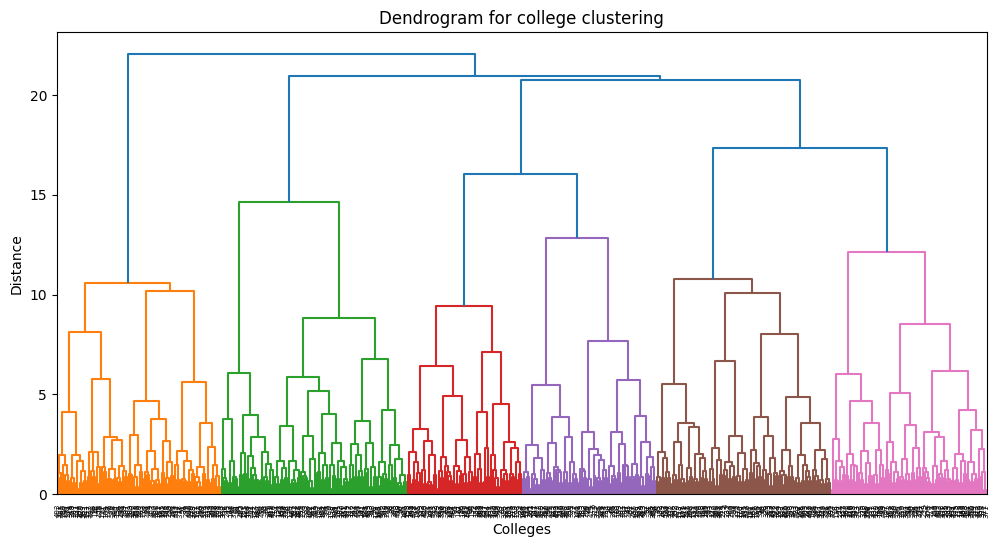

In [38]:
plt.figure(figsize = (12,6))
dendrogram = sch.dendrogram(sch.linkage(scaled_X,method="ward"))
plt.xlabel("Colleges"),plt.ylabel("Distance")
plt.show
plt.title("Dendrogram for college clustering")


In [48]:
hc = AgglomerativeClustering(n_clusters = 3)
clusters = hc.fit_predict(scaled_X)
clusters

array([2, 0, 0, 0, 0, 0, 1, 0, 2, 1, 0, 1, 0, 2, 0, 0, 2, 0, 1, 1, 0, 2,
       2, 0, 1, 0, 0, 0, 0, 0, 0, 2, 1, 2, 2, 0, 1, 0, 2, 1, 0, 1, 0, 0,
       2, 0, 1, 0, 0, 0, 0, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 2,
       0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 1, 2, 2, 1, 0, 0, 2, 2, 0, 1, 1, 2,
       0, 2, 1, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 2, 0, 0, 2, 0, 1, 0, 0, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 0, 2, 1, 0, 0, 0, 0,
       2, 0, 0, 1, 1, 2, 0, 2, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 2, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0, 1, 1, 1, 0, 2, 0, 0,
       1, 0, 0, 1, 0, 0, 2, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 0, 1, 0,

In [49]:
cd["College_Level"]= clusters
cd

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,2
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,0
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,0
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,0
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,0
...,...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5,0
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7,0
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3,1
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6,0


In [50]:
X["Level"] = clusters

In [56]:
X.groupby(by = "Level").agg(["mean"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
Level,,,,,
0,20.407051,121853.471154,67.278846,6.954583,6.509615
1,17.159091,156795.136364,85.568182,5.565682,3.965909
2,11.650000,175656.000000,59.790000,8.362500,6.080000


In [58]:
X.groupby(by = "Level").agg(["min"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,min,min,min,min,min
Level,,,,,
0,8,30404,40,2.00,3
1,8,39337,64,2.09,3
2,8,49065,40,2.01,3


In [59]:
X.groupby(by = "Level").agg(["max"])

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,max,max,max,max,max
Level,,,,,
0,29,249536,99,11.99,9
1,29,248803,99,11.96,9
2,20,249930,99,11.91,9


In [60]:
cluster_names = {0:"Average",1:"Best",2:"Emerging"}
X["Category"] = X["Level"].map(cluster_names)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Level,Category
0,14,113042,59,9.20,8,2,Emerging
1,27,115999,67,3.07,7,0,Average
2,22,47955,50,3.40,9,0,Average
3,18,67841,43,4.64,8,0,Average
4,15,100640,54,4.66,9,0,Average
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0,Average
496,12,39111,76,3.62,7,0,Average
497,16,199182,64,3.88,3,1,Best
498,10,46389,77,9.31,6,0,Average


# SUPERVISING LEARNING

In [78]:
input_data = X.drop(["Level","Category"],axis = 1)
output_data = X.Level

X_train,X_test,y_train,y_test = train_test_split(input_data,output_data, test_size = 0.20, random_state = 123, stratify = output_data, shuffle = True)

rf_model = RandomForestClassifier()
model = rf_model.fit(X_train,y_train)

y_test_pred = model.predict(X_test)

print("Accuracy Score: ",round(accuracy_score(y_test,y_test_pred),2))
print("Confusion Matrix: \n", confusion_matrix(y_test,y_test_pred))

Accuracy Score:  0.94
Confusion Matrix: 
 [[59  1  2]
 [ 1 17  0]
 [ 2  0 18]]


In [82]:
import pickle

pickle.dump(rf_model,open("college_level_prediction.pkl","wb"))